## Exploratory Data Analysis for IE7275-GroupA Project: I See You, ICU on MIMIC-IV dataset

Perform a EDA including:
   - Data profiling (shape, data types, missing values)
   - Statistical summaries
   - Outlier detection using both methods
   - Multiple visualizations (histogram, box plot, scatter plot)
   - Correlation analysis

In [2]:
# Load feature dataset into pandas DataFrame
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Data Profiling
print("[1. Data Profiling]")

df = pd.read_csv("features.csv")
df.head(10)


,subject_id,hadm_id,snapshot_time,y_24h,y_48h,age,gender_male,admission_type,admission_location,careunit,...,lactate_count24h,magnesium_count24h,pco2_count24h,ph_count24h,platelets_count24h,po2_count24h,potassium_count24h,sodium_count24h,troponin_t_count24h,wbc_count24h
0,10000032,22841357,2180-06-27 08:00:00,0,0,52,0,EW EMER.,EMERGENCY ROOM,Transplant,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0
1,10000032,25742920,2180-08-06 08:00:00,0,0,52,0,EW EMER.,EMERGENCY ROOM,Transplant,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0
2,10000032,25742920,2180-08-07 08:00:00,0,0,52,0,EW EMER.,EMERGENCY ROOM,Transplant,...,0.0,1.0,0.0,0.0,1.0,0.0,2.0,1.0,0.0,1.0
3,10000690,23280645,2150-09-17 08:00:00,0,0,86,0,EW EMER.,EMERGENCY ROOM,Thoracic Surgery,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,10000690,23280645,2150-09-18 08:00:00,0,0,86,0,EW EMER.,EMERGENCY ROOM,Thoracic Surgery,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,2.0,1.0
5,10000690,23280645,2150-09-19 08:00:00,0,0,86,0,EW EMER.,EMERGENCY ROOM,Thoracic Surgery,...,0.0,1.0,0.0,0.0,2.0,0.0,1.0,1.0,1.0,2.0
6,10000690,23280645,2150-09-20 08:00:00,0,0,86,0,EW EMER.,EMERGENCY ROOM,Thoracic Surgery,...,0.0,1.0,0.0,0.0,0.0,0.0,2.0,2.0,1.0,0.0
7,10000690,23280645,2150-09-21 08:00:00,0,0,86,0,EW EMER.,EMERGENCY ROOM,Thoracic Surgery,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0
8,10000690,23280645,2150-09-22 08:00:00,0,0,86,0,EW EMER.,EMERGENCY ROOM,Thoracic Surgery,...,0.0,1.0,0.0,0.0,3.0,0.0,2.0,2.0,0.0,3.0
9,10000690,23280645,2150-09-23 08:00:00,0,0,86,0,EW EMER.,EMERGENCY ROOM,Thoracic Surgery,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0


The distribution of the features

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 725334 entries, 0 to 725333
Columns: 143 entries, subject_id to wbc_count24h
dtypes: float64(122), int64(16), object(5)
memory usage: 791.3+ MB


In [4]:
df.dtypes

subject_id               int64
hadm_id                  int64
snapshot_time           object
y_24h                    int64
y_48h                    int64
                        ...   
po2_count24h           float64
potassium_count24h     float64
sodium_count24h        float64
troponin_t_count24h    float64
wbc_count24h           float64
Length: 143, dtype: object

In [6]:
df['admission_type'].unique()

array(['EW EMER.', 'DIRECT EMER.', 'EU OBSERVATION', 'OBSERVATION ADMIT',
       'DIRECT OBSERVATION', 'AMBULATORY OBSERVATION', 'URGENT'],
      dtype=object)

In [7]:
df['admission_location'].unique()

array(['EMERGENCY ROOM', 'CLINIC REFERRAL', 'PHYSICIAN REFERRAL',
       'TRANSFER FROM SKILLED NURSING FACILITY', 'TRANSFER FROM HOSPITAL',
       'WALK-IN/SELF REFERRAL', 'PROCEDURE SITE', 'PACU',
       'INFORMATION NOT AVAILABLE', 'AMBULATORY SURGERY TRANSFER',
       'INTERNAL TRANSFER TO OR FROM PSYCH'], dtype=object)

In [8]:
df['careunit'].unique()

array(['Transplant', 'Thoracic Surgery', 'Neurology',
       'Surgery/Pancreatic/Biliary/Bariatric', 'Hematology/Oncology',
       'Vascular', 'Medicine', 'Med/Surg',
       'Medical/Surgical (Gynecology)', 'Med/Surg/GYN',
       'Surgery/Vascular/Intermediate', 'Medicine/Cardiology',
       'Surgery/Trauma', 'Cardiology Surgery Intermediate',
       'Surgical Intermediate', 'Med/Surg/Trauma',
       'Hematology/Oncology Intermediate', 'Cardiac Surgery',
       'Medicine/Cardiology Intermediate', 'Cardiology', 'Surgery',
       'Neuro Intermediate', 'Oncology', 'Neuro Stepdown'], dtype=object)

In [11]:
# value_counts() counts how many times each distinct value appears in a column.
print(df["admission_type"].value_counts(), "\n")   # "\n" prints a blank line

# Each failure-mode column holds 1 (this mode occurred) or 0 (it did not),
# so adding up a column counts the records with that mode.
# Double brackets, [[...]], select several columns at once.
#print("Records flagged with each failure mode:")
#print(ai4i[["TWF", "HDF", "PWF", "OSF", "RNF"]].sum())

admission_type
EW EMER.                  315458
OBSERVATION ADMIT         239302
DIRECT EMER.               79127
URGENT                     42345
EU OBSERVATION             33263
DIRECT OBSERVATION         12493
AMBULATORY OBSERVATION      3346
Name: count, dtype: int64 



In [12]:
# value_counts() counts how many times each distinct value appears in a column.
print(df["admission_location"].value_counts(), "\n")   # "\n" prints a blank line


admission_location
EMERGENCY ROOM                            311927
PHYSICIAN REFERRAL                        177478
WALK-IN/SELF REFERRAL                      80719
TRANSFER FROM HOSPITAL                     71418
CLINIC REFERRAL                            47664
TRANSFER FROM SKILLED NURSING FACILITY     21975
PROCEDURE SITE                              7832
PACU                                        5487
AMBULATORY SURGERY TRANSFER                  605
INFORMATION NOT AVAILABLE                    211
INTERNAL TRANSFER TO OR FROM PSYCH            18
Name: count, dtype: int64 



In [13]:
# value_counts() counts how many times each distinct value appears in a column.
print(df["careunit"].value_counts(), "\n")   # "\n" prints a blank line


careunit
Medicine                                224253
Hematology/Oncology                      83308
Transplant                               62363
Med/Surg                                 57151
Hematology/Oncology Intermediate         51568
Medicine/Cardiology                      48469
Vascular                                 34517
Neurology                                30313
Medicine/Cardiology Intermediate         19962
Med/Surg/GYN                             19576
Surgery/Trauma                           17349
Surgery                                  17111
Med/Surg/Trauma                          16510
Surgery/Pancreatic/Biliary/Bariatric      7960
Surgery/Vascular/Intermediate             7393
Cardiac Surgery                           6614
Medical/Surgical (Gynecology)             5444
Cardiology Surgery Intermediate           4497
Neuro Intermediate                        2442
Oncology                                  2440
Thoracic Surgery                          2118
Surg

=== 1. Data Profiling ===

[Data Shape]
(725334, 143)

[Data Types and Missing Values]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 725334 entries, 0 to 725333
Columns: 143 entries, subject_id to wbc_count24h
dtypes: float64(122), int64(16), object(5)
memory usage: 791.3+ MB
None

[Missing Values Count]
omr_bmi              249367
omr_dbp              194377
omr_sbp              194012
omr_weight_lbs       217634
curr_service             34
                      ...  
po2_max24h           710607
potassium_max24h     207222
sodium_max24h        208752
troponin_t_max24h    702420
wbc_max24h           219991
Length: 89, dtype: int64

[2. Statistical Summary (Numerical Variables)]
         subject_id       hadm_id          y_24h          y_48h  \
count  7.253340e+05  7.253340e+05  725334.000000  725334.000000   
mean   1.500815e+07  2.500928e+07       0.008985       0.015498   
std    2.882653e+06  2.891668e+06       0.094362       0.123521   
min    1.000003e+07  2.000002e+07       0

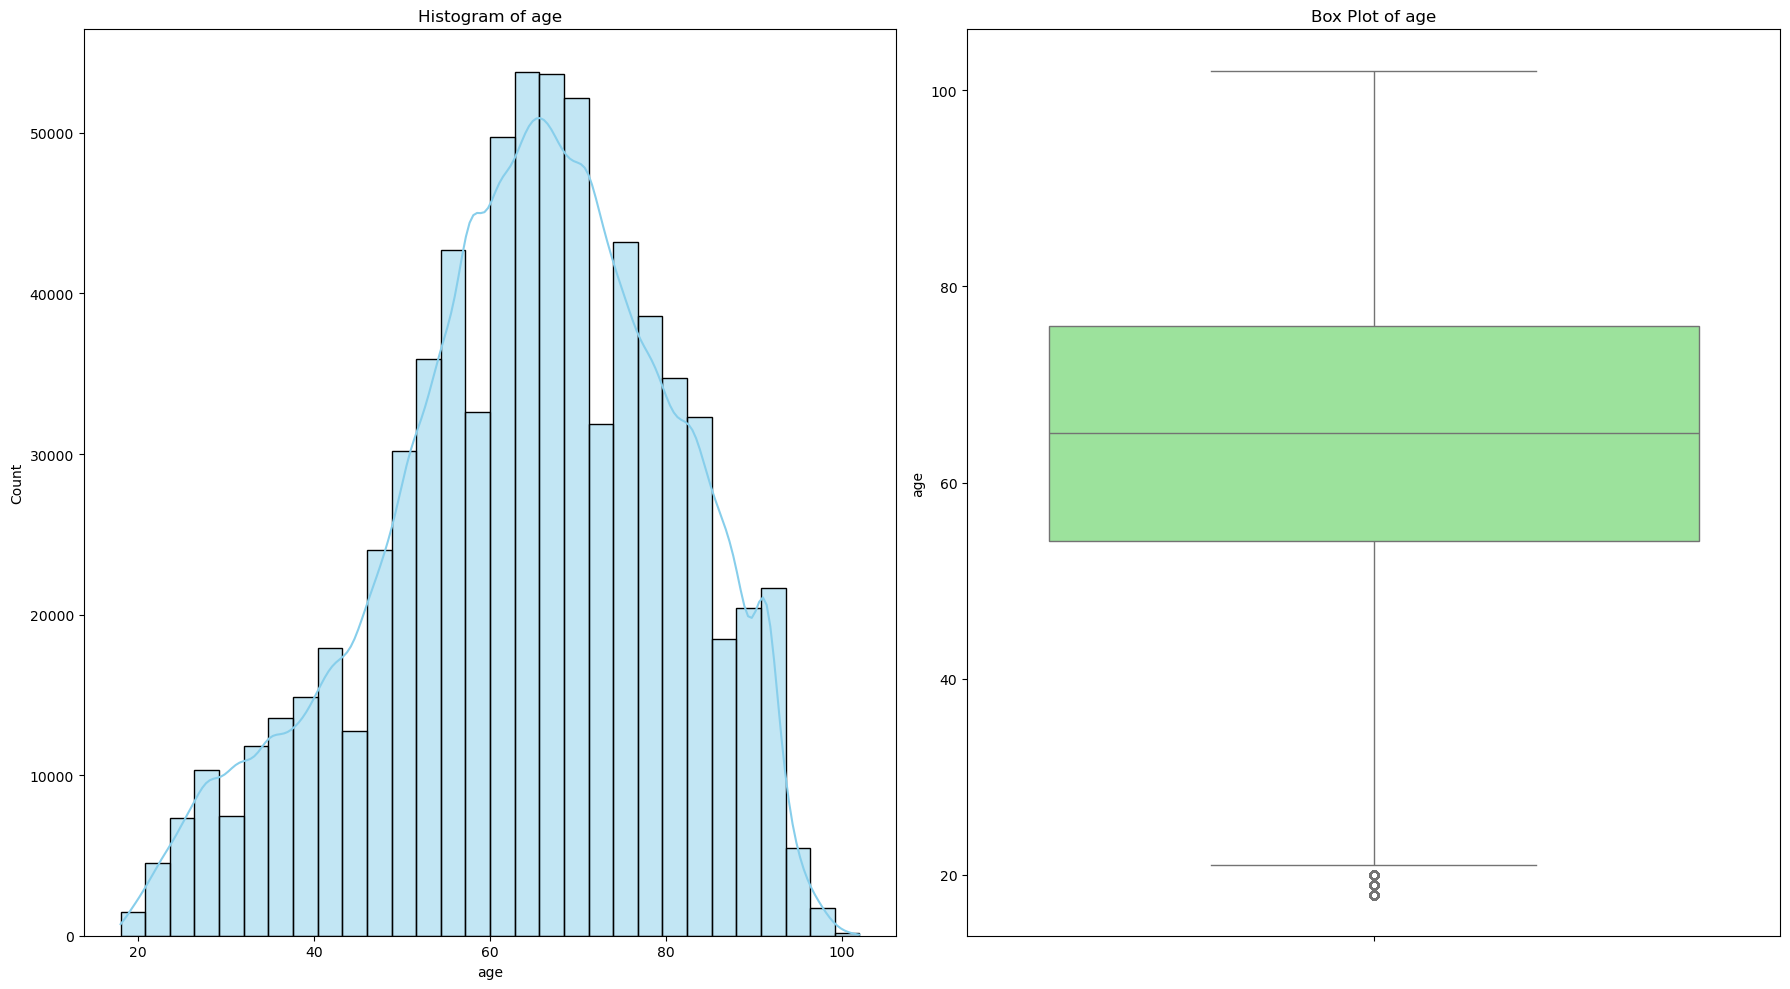

In [3]:


print("\n[Data Shape]")
print(df.shape)

print("\n[Data Types and Missing Values]")
print(df.info())

print("\n[Missing Values Count]")
print(df.isnull().sum()[df.isnull().sum() > 0])

# 2. Statistical Summaries
print("\n[2. Statistical Summary (Numerical Variables)]")
print(df.describe())

# 3. Outlier Detection (Two methods: IQR method, Z-score method)
print("\n[3. Outlier Detection]")

# Select a target numerical column (e.g., 'age' or the first numerical column)
target_col = 'age' if 'age' in df.columns else df.select_dtypes(include=np.number).columns[0]
print(f"Target column for outlier detection: {target_col}")

# Method A: IQR (Interquartile Range) Method
Q1 = df[target_col].quantile(0.25)
Q3 = df[target_col].quantile(0.75)
IQR = Q3 - Q1
lower_bound_iqr = Q1 - 1.5 * IQR
upper_bound_iqr = Q3 + 1.5 * IQR
outliers_iqr = df[(df[target_col] < lower_bound_iqr) | (df[target_col] > upper_bound_iqr)]
print(f"- Number of outliers (IQR method): {len(outliers_iqr)}")

# Method B: Z-score Method (|Z| > 3)
mean_val = df[target_col].mean()
std_val = df[target_col].std()
z_scores = (df[target_col] - mean_val) / std_val
outliers_z = df[abs(z_scores) > 3]
print(f"- Number of outliers (Z-score method): {len(outliers_z)}")

# 4. Visualizations (Histogram, Box Plot, Scatter Plot)
print("\n=== 4. Generating Visualizations ===")
fig, axes = plt.subplots(1, 2, figsize=(18, 10))

# 4-1. Histogram (Distribution)
sns.histplot(df[target_col], kde=True, ax=axes[0], color='skyblue', bins=30)
axes[0].set_title(f"Histogram of {target_col}")
axes[0].set_xlabel(target_col)
axes[0].set_ylabel("Count")

# 4-2. Box Plot (Outlier visualization)
sns.boxplot(y=df[target_col], ax=axes[1], color='lightgreen')
axes[1].set_title(f"Box Plot of {target_col}")
axes[1].set_ylabel(target_col)

# 4-3. Scatter Plot (Relationship between target_col and another numerical column)
#numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
#if len(numeric_cols) >= 2:
#    second_col = numeric_cols[1] if numeric_cols[0] == target_col else numeric_cols[0]
#    sns.scatterplot(x=df[target_col], y=df[second_col], ax=axes[2], alpha=0.6, color='salmon')
#    axes[2].set_title(f"Scatter Plot: {target_col} vs {second_col}")
#    axes[2].set_xlabel(target_col)
#    axes[2].set_ylabel(second_col)

plt.tight_layout()
plt.savefig("eda_visualizations.png")
plt.show()


In [9]:
# Define your mapping

#admission_type	admission_location	careunit

admit_type_map = {'EW EMER.': 1, 'DIRECT EMER.':2, 'EU OBSERVATION':3, 'OBSERVATION ADMIT':4,
       'DIRECT OBSERVATION':5, 'AMBULATORY OBSERVATION':6, 'URGENT':7}

# Create the column
df['admit_type'] = df['admission_type'].map(admit_type_map)

# Display the result
print(df.head())

   subject_id   hadm_id        snapshot_time  y_24h  y_48h  age  gender_male  \
0    10000032  22841357  2180-06-27 08:00:00      0      0   52            0   
1    10000032  25742920  2180-08-06 08:00:00      0      0   52            0   
2    10000032  25742920  2180-08-07 08:00:00      0      0   52            0   
3    10000690  23280645  2150-09-17 08:00:00      0      0   86            0   
4    10000690  23280645  2150-09-18 08:00:00      0      0   86            0   

  admission_type admission_location          careunit  ...  \
0       EW EMER.     EMERGENCY ROOM        Transplant  ...   
1       EW EMER.     EMERGENCY ROOM        Transplant  ...   
2       EW EMER.     EMERGENCY ROOM        Transplant  ...   
3       EW EMER.     EMERGENCY ROOM  Thoracic Surgery  ...   
4       EW EMER.     EMERGENCY ROOM  Thoracic Surgery  ...   

   magnesium_count24h  pco2_count24h  ph_count24h  platelets_count24h  \
0                 1.0            0.0          0.0                 1.0   


Class Imbalance

6,517 transfer in 725,334 records: 0.90%
11,241 transfer in 725,334 records: 1.55%


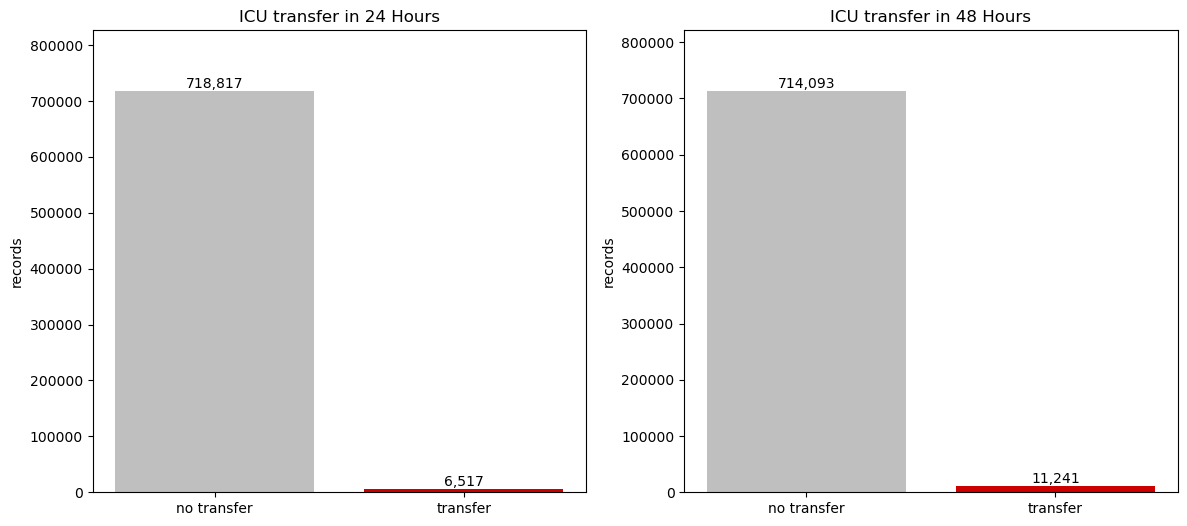

In [22]:
# Count the records in each class: 0 = no transfer, 1 = transfer.
# sort_index() puts the result in the order 0, 1.
counts_1d = df['y_24h'].value_counts().sort_index()
counts_2d = df['y_48h'].value_counts().sort_index()

# The mean of a column of 0s and 1s is the share of 1s, which is the failure rate.
rate_1d = df['y_24h'].mean()
rate_2d = df['y_48h'].mean()

# An f-string, written f"...", fills in the values inside {curly braces}.
# ":," adds thousands separators, and ":.2%" shows a percentage with two decimals.
print(f"{counts_1d[1]:,} transfer in {len(df):,} records: {rate_1d:.2%}")
print(f"{counts_2d[1]:,} transfer in {len(df):,} records: {rate_2d:.2%}")

# Draw a bar chart of the two counts.
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))

axes[0].bar(["no transfer", "transfer"], counts_1d.values, color=["#BFBFBF", "#CC0000"])
for i, v in enumerate(counts_1d.values):     # enumerate gives each position i and its value v
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")   # write the count above each bar
#axes[0].set_ylim(0, counts_1d.max() * 1.15)       # leave room above the tallest bar for its label
axes[0].set_ylabel("records")
axes[0].set_title("ICU transfer in 24 Hours")

axes[1].bar(["no transfer", "transfer"], counts_2d.values, color=["#BFBFBF", "#CC0000"])
for i, v in enumerate(counts_2d.values):     # enumerate gives each position i and its value v
    axes[1].text(i, v, f"{v:,}", ha="center", va="bottom")   # write the count above each bar
#axes[1].set_ylim(0, counts_2d.max() * 1.15)       # leave room above the tallest bar for its label
axes[1].set_ylabel("records")
axes[1].set_title("ICU transfer in 48 Hours")
plt.show()

The distribution of the target:  


--- Feature Group: albumin ---
                  albumin_last  albumin_delta  albumin_min24h  albumin_max24h  \
albumin_last          1.000000       0.202964        0.996323        0.993697   
albumin_delta         0.202964       1.000000        0.163386        0.147703   
albumin_min24h        0.996323       0.163386        1.000000        0.990141   
albumin_max24h        0.993697       0.147703        0.990141        1.000000   
albumin_count24h     -0.018187       0.036278       -0.075705        0.023776   

                  albumin_count24h  
albumin_last             -0.018187  
albumin_delta             0.036278  
albumin_min24h           -0.075705  
albumin_max24h            0.023776  
albumin_count24h          1.000000  


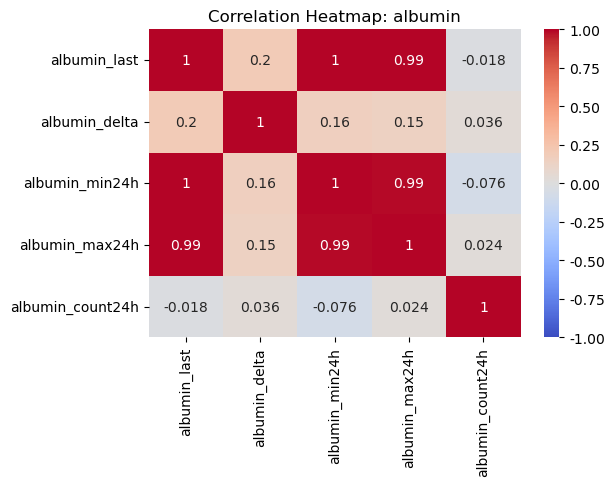


--- Feature Group: anion ---
                    anion_gap_last  anion_gap_delta  anion_gap_min24h  \
anion_gap_last            1.000000         0.369840          0.972075   
anion_gap_delta           0.369840         1.000000          0.284346   
anion_gap_min24h          0.972075         0.284346          1.000000   
anion_gap_max24h          0.938744         0.189469          0.914972   
anion_gap_count24h        0.028044        -0.039289         -0.105890   

                    anion_gap_max24h  anion_gap_count24h  
anion_gap_last              0.938744            0.028044  
anion_gap_delta             0.189469           -0.039289  
anion_gap_min24h            0.914972           -0.105890  
anion_gap_max24h            1.000000            0.191533  
anion_gap_count24h          0.191533            1.000000  


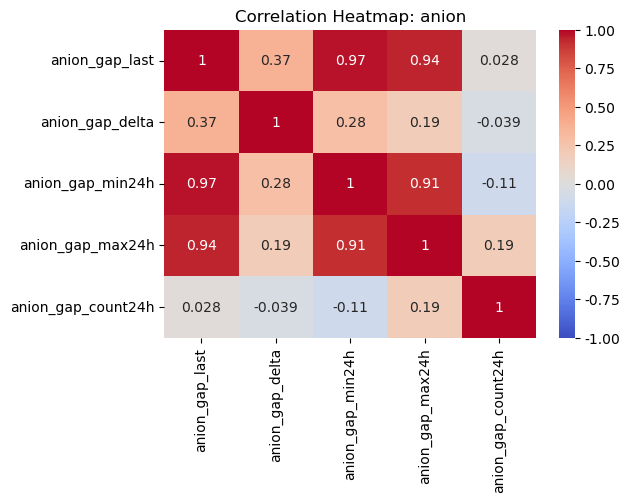


--- Feature Group: bicarbonate ---
                      bicarbonate_last  bicarbonate_delta  bicarbonate_min24h  \
bicarbonate_last              1.000000           0.272625            0.969797   
bicarbonate_delta             0.272625           1.000000            0.156707   
bicarbonate_min24h            0.969797           0.156707            1.000000   
bicarbonate_max24h            0.983375           0.195174            0.955286   
bicarbonate_count24h          0.009865           0.016692           -0.091003   

                      bicarbonate_max24h  bicarbonate_count24h  
bicarbonate_last                0.983375              0.009865  
bicarbonate_delta               0.195174              0.016692  
bicarbonate_min24h              0.955286             -0.091003  
bicarbonate_max24h              1.000000              0.119315  
bicarbonate_count24h            0.119315              1.000000  


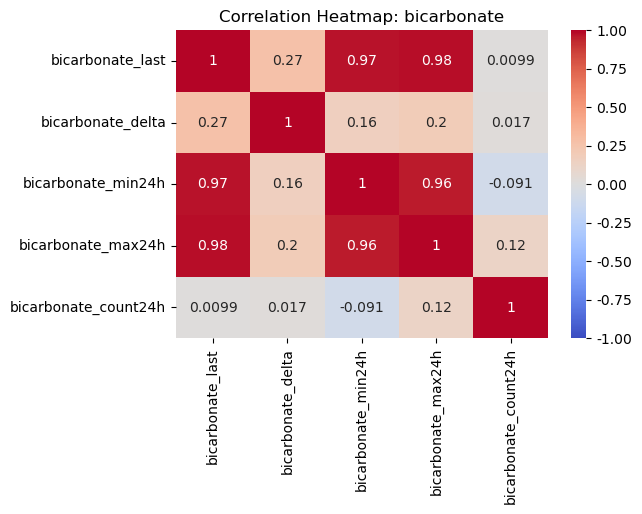


--- Feature Group: bilirubin ---
                    bilirubin_last  bilirubin_delta  bilirubin_min24h  \
bilirubin_last            1.000000         0.099762          0.999030   
bilirubin_delta           0.099762         1.000000          0.085125   
bilirubin_min24h          0.999030         0.085125          1.000000   
bilirubin_max24h          0.998783         0.080194          0.997913   
bilirubin_count24h        0.159578        -0.006846          0.060491   

                    bilirubin_max24h  bilirubin_count24h  
bilirubin_last              0.998783            0.159578  
bilirubin_delta             0.080194           -0.006846  
bilirubin_min24h            0.997913            0.060491  
bilirubin_max24h            1.000000            0.087837  
bilirubin_count24h          0.087837            1.000000  


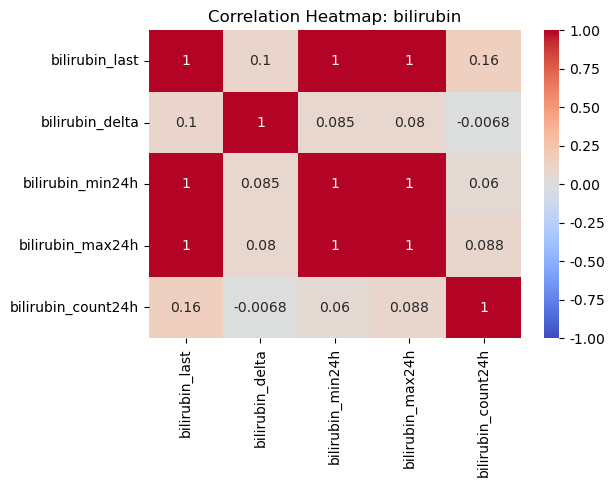


--- Feature Group: bun ---
              bun_last  bun_delta  bun_min24h  bun_max24h  bun_count24h
bun_last      1.000000   0.096390    0.996974    0.992646      0.150253
bun_delta     0.096390   1.000000    0.069889    0.036792      0.002543
bun_min24h    0.996974   0.069889    1.000000    0.989852      0.110994
bun_max24h    0.992646   0.036792    0.989852    1.000000      0.179495
bun_count24h  0.150253   0.002543    0.110994    0.179495      1.000000


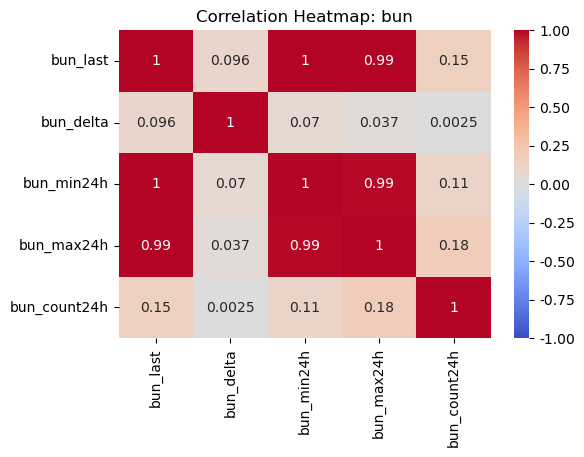


--- Feature Group: calcium ---
                  calcium_last  calcium_delta  calcium_min24h  calcium_max24h  \
calcium_last          1.000000       0.244807        0.980185        0.975238   
calcium_delta         0.244807       1.000000        0.161410        0.130727   
calcium_min24h        0.980185       0.161410        1.000000        0.956641   
calcium_max24h        0.975238       0.130727        0.956641        1.000000   
calcium_count24h     -0.036493      -0.038038       -0.100326        0.093107   

                  calcium_count24h  
calcium_last             -0.036493  
calcium_delta            -0.038038  
calcium_min24h           -0.100326  
calcium_max24h            0.093107  
calcium_count24h          1.000000  


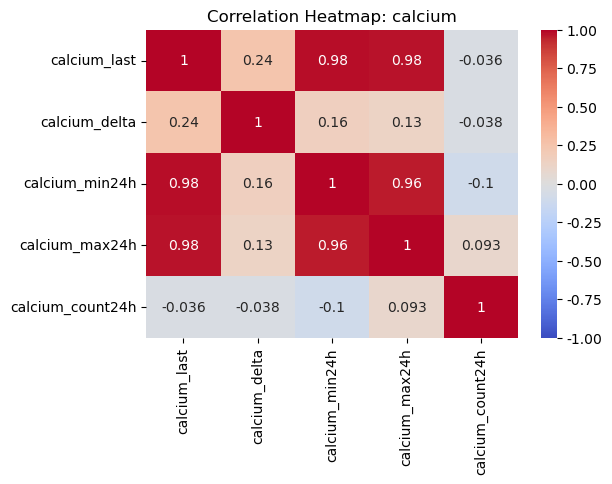


--- Feature Group: chloride ---
                   chloride_last  chloride_delta  chloride_min24h  \
chloride_last           1.000000        0.221598         0.980947   
chloride_delta          0.221598        1.000000         0.133460   
chloride_min24h         0.980947        0.133460         1.000000   
chloride_max24h         0.984194        0.151903         0.966661   
chloride_count24h      -0.089314        0.015626        -0.191229   

                   chloride_max24h  chloride_count24h  
chloride_last             0.984194          -0.089314  
chloride_delta            0.151903           0.015626  
chloride_min24h           0.966661          -0.191229  
chloride_max24h           1.000000          -0.014542  
chloride_count24h        -0.014542           1.000000  


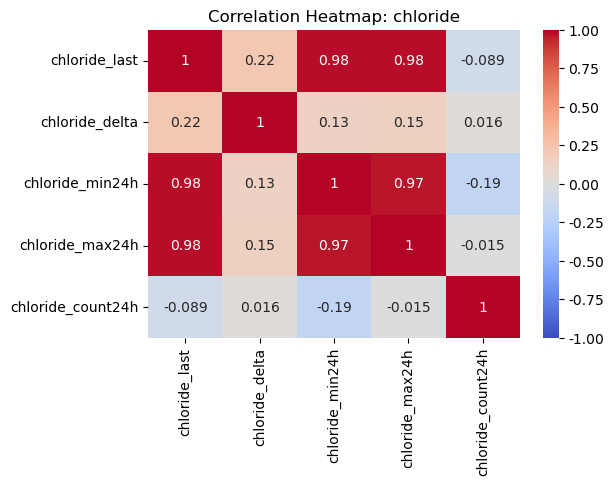


--- Feature Group: creatinine ---
                     creatinine_last  creatinine_delta  creatinine_min24h  \
creatinine_last             1.000000          0.045551           0.997668   
creatinine_delta            0.045551          1.000000           0.025739   
creatinine_min24h           0.997668          0.025739           1.000000   
creatinine_max24h           0.992101         -0.020340           0.989959   
creatinine_count24h         0.077670         -0.010407           0.042130   

                     creatinine_max24h  creatinine_count24h  
creatinine_last               0.992101             0.077670  
creatinine_delta             -0.020340            -0.010407  
creatinine_min24h             0.989959             0.042130  
creatinine_max24h             1.000000             0.091420  
creatinine_count24h           0.091420             1.000000  


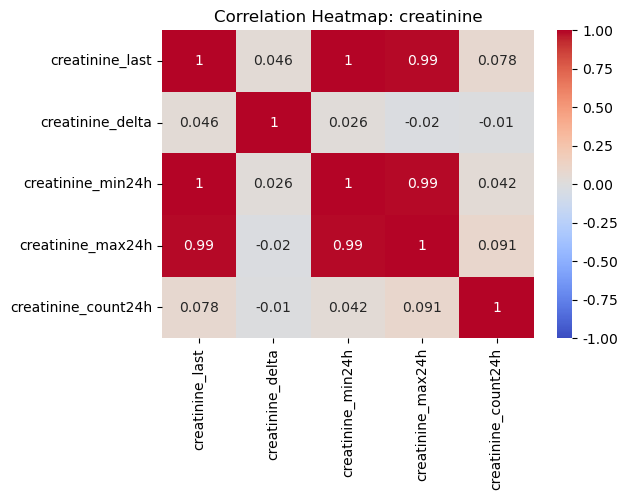


--- Feature Group: glucose ---
                  glucose_last  glucose_delta  glucose_min24h  glucose_max24h  \
glucose_last          1.000000       0.434276        0.927638        0.858754   
glucose_delta         0.434276       1.000000        0.315309        0.124858   
glucose_min24h        0.927638       0.315309        1.000000        0.798008   
glucose_max24h        0.858754       0.124858        0.798008        1.000000   
glucose_count24h      0.069315      -0.014059       -0.084196        0.215541   

                  glucose_count24h  
glucose_last              0.069315  
glucose_delta            -0.014059  
glucose_min24h           -0.084196  
glucose_max24h            0.215541  
glucose_count24h          1.000000  


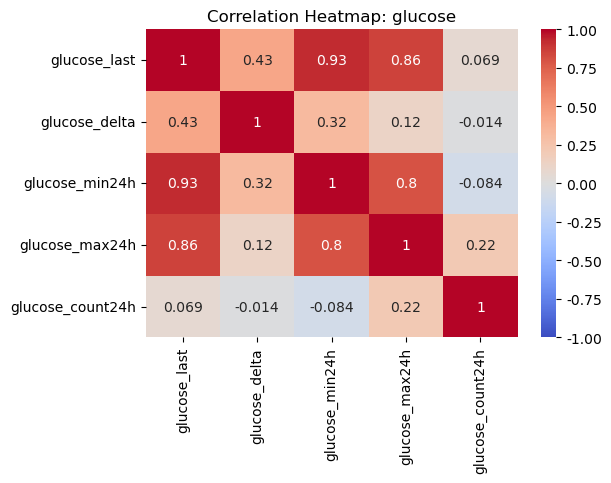


--- Feature Group: hemoglobin ---
                     hemoglobin_last  hemoglobin_delta  hemoglobin_min24h  \
hemoglobin_last             1.000000          0.131430           0.992569   
hemoglobin_delta            0.131430          1.000000           0.083813   
hemoglobin_min24h           0.992569          0.083813           1.000000   
hemoglobin_max24h           0.988797          0.058563           0.981923   
hemoglobin_count24h        -0.146383         -0.044952          -0.148456   

                     hemoglobin_max24h  hemoglobin_count24h  
hemoglobin_last               0.988797            -0.146383  
hemoglobin_delta              0.058563            -0.044952  
hemoglobin_min24h             0.981923            -0.148456  
hemoglobin_max24h             1.000000            -0.013863  
hemoglobin_count24h          -0.013863             1.000000  


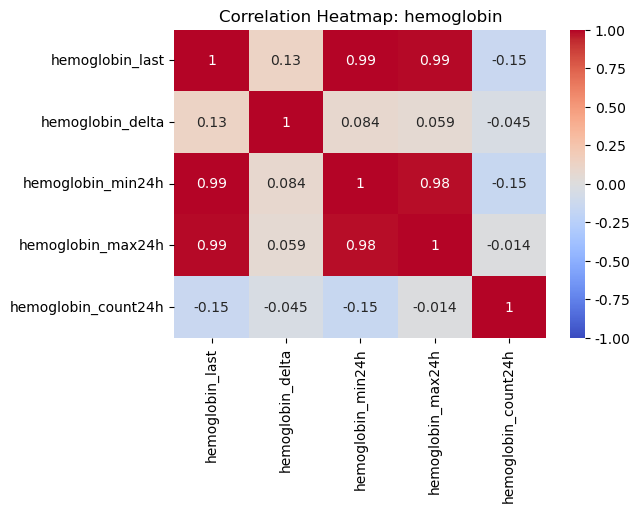


--- Feature Group: inr ---
              inr_last  inr_delta  inr_min24h  inr_max24h  inr_count24h
inr_last      1.000000   0.117615    0.989916    0.963266      0.236970
inr_delta     0.117615   1.000000    0.091437   -0.013097     -0.007987
inr_min24h    0.989916   0.091437    1.000000    0.954094      0.048988
inr_max24h    0.963266  -0.013097    0.954094    1.000000      0.152051
inr_count24h  0.236970  -0.007987    0.048988    0.152051      1.000000


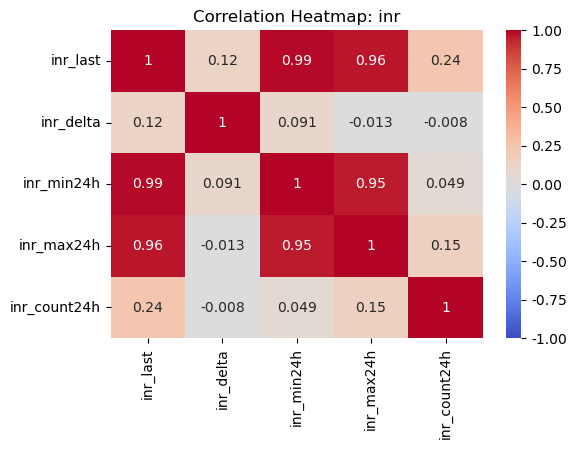


--- Feature Group: lactate ---
                  lactate_last  lactate_delta  lactate_min24h  lactate_max24h  \
lactate_last          1.000000       0.152808        0.972551        0.854403   
lactate_delta         0.152808       1.000000        0.114976       -0.232869   
lactate_min24h        0.972551       0.114976        1.000000        0.831617   
lactate_max24h        0.854403      -0.232869        0.831617        1.000000   
lactate_count24h      0.108638      -0.007083        0.078379        0.413710   

                  lactate_count24h  
lactate_last              0.108638  
lactate_delta            -0.007083  
lactate_min24h            0.078379  
lactate_max24h            0.413710  
lactate_count24h          1.000000  


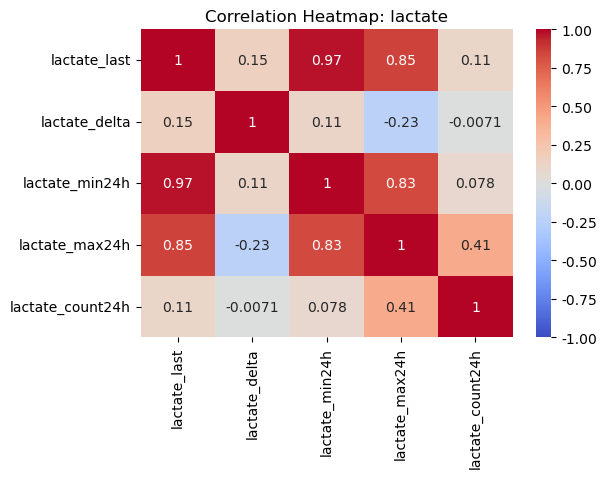


--- Feature Group: magnesium ---
                    magnesium_last  magnesium_delta  magnesium_min24h  \
magnesium_last            1.000000         0.394792          0.916492   
magnesium_delta           0.394792         1.000000          0.187135   
magnesium_min24h          0.916492         0.187135          1.000000   
magnesium_max24h          0.956902         0.273083          0.874510   
magnesium_count24h        0.074339         0.002380         -0.046110   

                    magnesium_max24h  magnesium_count24h  
magnesium_last              0.956902            0.074339  
magnesium_delta             0.273083            0.002380  
magnesium_min24h            0.874510           -0.046110  
magnesium_max24h            1.000000            0.226467  
magnesium_count24h          0.226467            1.000000  


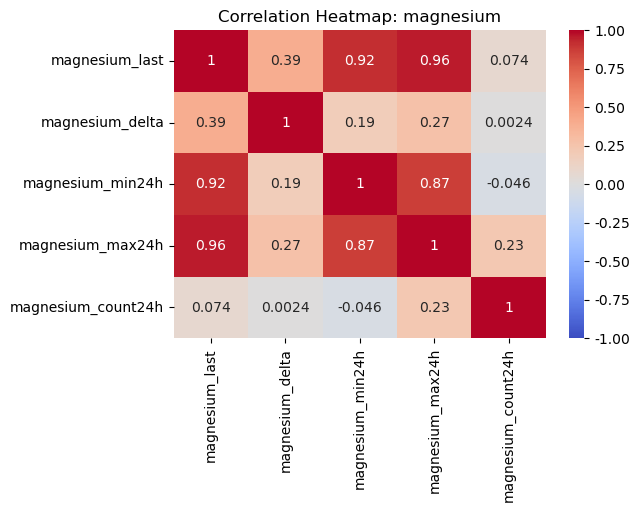


--- Feature Group: pco2 ---
               pco2_last  pco2_delta  pco2_min24h  pco2_max24h  pco2_count24h
pco2_last       1.000000    0.234936     0.972596     0.963412       0.035245
pco2_delta      0.234936    1.000000     0.087270     0.037907      -0.023122
pco2_min24h     0.972596    0.087270     1.000000     0.937117      -0.085819
pco2_max24h     0.963412    0.037907     0.937117     1.000000       0.150709
pco2_count24h   0.035245   -0.023122    -0.085819     0.150709       1.000000


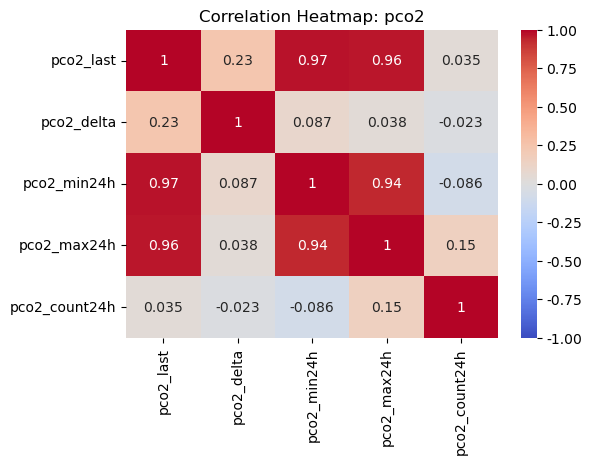


--- Feature Group: ph ---
              ph_last  ph_delta  ph_min24h  ph_max24h  ph_count24h
ph_last      1.000000  0.340732   0.945093   0.957058    -0.030148
ph_delta     0.340732  1.000000   0.114362   0.149892     0.005443
ph_min24h    0.945093  0.114362   1.000000   0.903356    -0.248927
ph_max24h    0.957058  0.149892   0.903356   1.000000     0.061722
ph_count24h -0.030148  0.005443  -0.248927   0.061722     1.000000


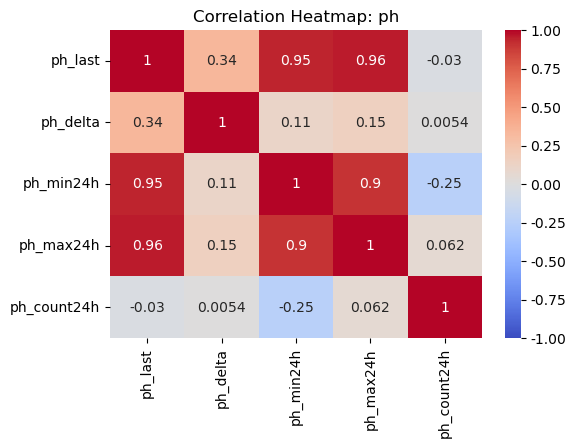


--- Feature Group: platelets ---
                    platelets_last  platelets_delta  platelets_min24h  \
platelets_last            1.000000         0.116782          0.997602   
platelets_delta           0.116782         1.000000          0.095714   
platelets_min24h          0.997602         0.095714          1.000000   
platelets_max24h          0.996540         0.082082          0.994362   
platelets_count24h       -0.103722        -0.031430         -0.095594   

                    platelets_max24h  platelets_count24h  
platelets_last              0.996540           -0.103722  
platelets_delta             0.082082           -0.031430  
platelets_min24h            0.994362           -0.095594  
platelets_max24h            1.000000           -0.030820  
platelets_count24h         -0.030820            1.000000  


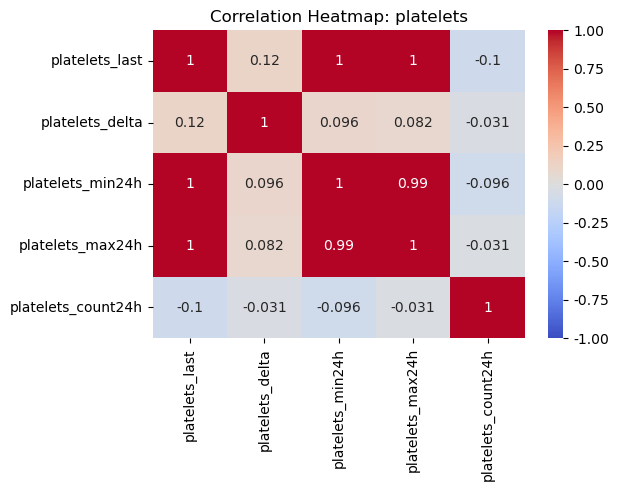


--- Feature Group: po2 ---
              po2_last  po2_delta  po2_min24h  po2_max24h  po2_count24h
po2_last      1.000000   0.469644    0.941049    0.941343      0.017617
po2_delta     0.469644   1.000000    0.279058    0.218069      0.016651
po2_min24h    0.941049   0.279058    1.000000    0.883983     -0.098943
po2_max24h    0.941343   0.218069    0.883983    1.000000      0.218576
po2_count24h  0.017617   0.016651   -0.098943    0.218576      1.000000


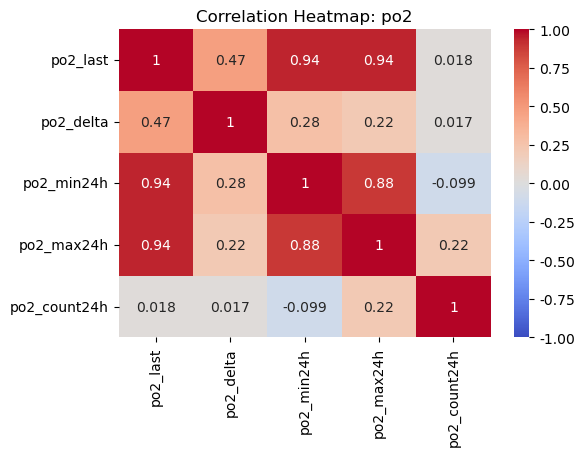


--- Feature Group: potassium ---
                    potassium_last  potassium_delta  potassium_min24h  \
potassium_last            1.000000         0.350208          0.946520   
potassium_delta           0.350208         1.000000          0.207591   
potassium_min24h          0.946520         0.207591          1.000000   
potassium_max24h          0.921845         0.137376          0.873878   
potassium_count24h        0.005947        -0.022095         -0.130796   

                    potassium_max24h  potassium_count24h  
potassium_last              0.921845            0.005947  
potassium_delta             0.137376           -0.022095  
potassium_min24h            0.873878           -0.130796  
potassium_max24h            1.000000            0.202292  
potassium_count24h          0.202292            1.000000  


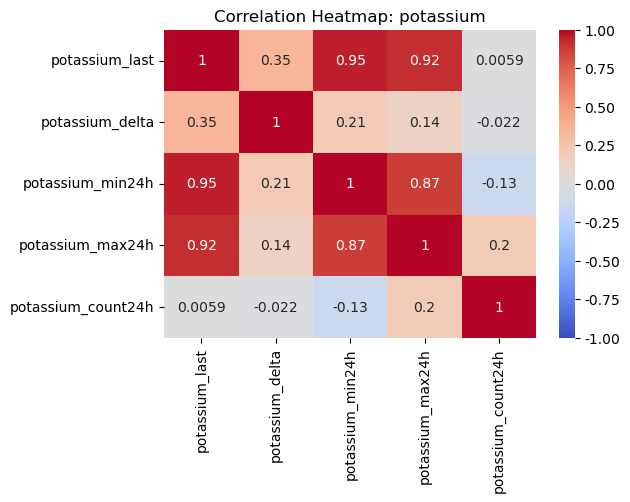


--- Feature Group: sodium ---
                 sodium_last  sodium_delta  sodium_min24h  sodium_max24h  \
sodium_last         1.000000      0.277456       0.972122       0.971085   
sodium_delta        0.277456      1.000000       0.173125       0.169923   
sodium_min24h       0.972122      0.173125       1.000000       0.946133   
sodium_max24h       0.971085      0.169923       0.946133       1.000000   
sodium_count24h    -0.069237     -0.006441      -0.187124       0.045178   

                 sodium_count24h  
sodium_last            -0.069237  
sodium_delta           -0.006441  
sodium_min24h          -0.187124  
sodium_max24h           0.045178  
sodium_count24h         1.000000  


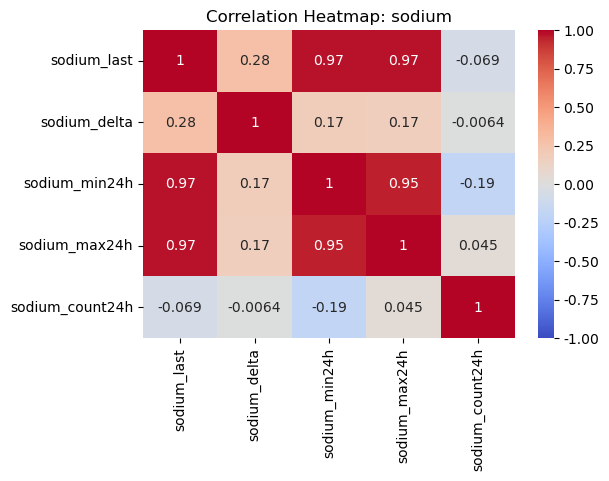


--- Feature Group: troponin ---
                     troponin_t_last  troponin_t_delta  troponin_t_min24h  \
troponin_t_last             1.000000          0.063834           0.981591   
troponin_t_delta            0.063834          1.000000           0.139688   
troponin_t_min24h           0.981591          0.139688           1.000000   
troponin_t_max24h           0.995805          0.185339           0.977562   
troponin_t_count24h         0.104482          0.047032           0.064201   

                     troponin_t_max24h  troponin_t_count24h  
troponin_t_last               0.995805             0.104482  
troponin_t_delta              0.185339             0.047032  
troponin_t_min24h             0.977562             0.064201  
troponin_t_max24h             1.000000             0.113835  
troponin_t_count24h           0.113835             1.000000  


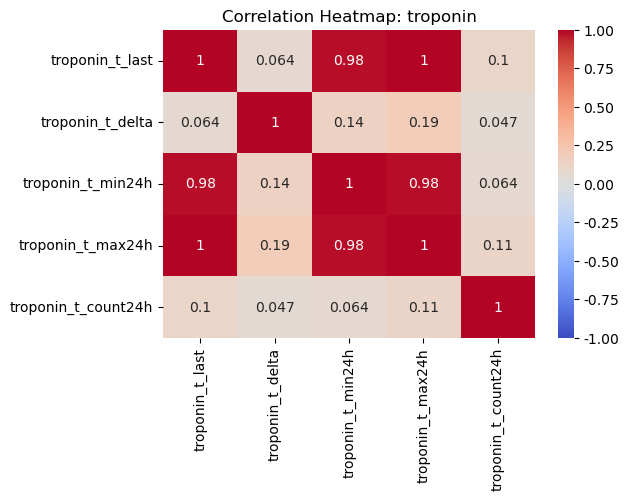


--- Feature Group: wbc ---
              wbc_last  wbc_delta  wbc_min24h  wbc_max24h  wbc_count24h
wbc_last      1.000000   0.105168    0.993672    0.990968      0.014913
wbc_delta     0.105168   1.000000    0.082474    0.062099     -0.005416
wbc_min24h    0.993672   0.082474    1.000000    0.985267     -0.009568
wbc_max24h    0.990968   0.062099    0.985267    1.000000      0.077558
wbc_count24h  0.014913  -0.005416   -0.009568    0.077558      1.000000


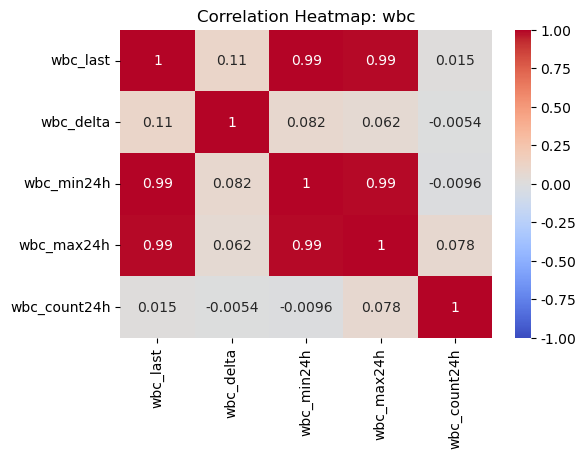

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

feat_df = df.iloc[:, 38:143]
feat_df.head(10)

# Creat feature prefixes
prefixes = feat_df.columns.str.split('_').str[0].unique()

for prefix in prefixes:
    # Filtering columns on prefixes 
    df_check = feat_df.filter(regex=f'^{prefix}_')
    
    # Correlation matrix on those grouped features
    if df_check.shape[1] > 1:
        print(f"\n--- Feature Group: {prefix} ---")
        corr_matrix = df_check.corr(method='pearson')
        print(corr_matrix)
        
        # Heatmap
        plt.figure(figsize=(6, 4))
        sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
        plt.title(f"Correlation Heatmap: {prefix}")
        plt.show()

Dimension reduction 
- Remove *_min24h/_max24h features based on correlation matrix result. 
- Reduce *_count24h from 21 to 9 per lab testing group.